# Meal Delivery Demand Forecasting with a Stacking Ensemble (Meal Delivery Dataset)

This notebook applies the method of `canteen_methodology.ipynb` to `datasets/meal_delivery_dataset.csv`, which records the weekly orders of each meal at the fulfilment centres of a meal delivery company. One centre is used (Section 0). It compares six models: Random Forest, XGBoost, SVR, LSTM, and two stacking ensembles that combine them through a Ridge regression meta-learner.

Before any modelling, Section 1 checks the data quality: missing values, duplicate records, invalid values, consistency between the prices, outliers, unusual weeks and how complete each meal's weekly records are. No problems that need fixing are found, so the data is used as it is.

| Section | Content |
|---|---|
| 0 | Setup: dataset location, libraries, configuration |
| 1 | Data loading and data quality checks |
| 2 | Feature engineering: lagged orders |
| 3 | Data analysis |
| 4 | One-hot encoding, train/test split, scaling |
| 5 | Evaluation metrics |
| 6 | Random Forest, XGBoost and SVR with grid search |
| 7 | LSTM |
| 8 | Stacking 1: RF + XGBoost + SVR → Ridge |
| 9 | Stacking 2: RF + XGBoost + SVR + LSTM → Ridge |
| 10 | Results and plots |

## 0. Setup
This section locates the dataset, imports the libraries and sets the configuration used throughout the notebook.

In [1]:
# Locate the dataset. On Google Colab the GitHub repository is cloned first;
# when run locally, the notebook already sits next to the dataset in the repository folder.
import os, sys
GITHUB_USER = "yklee7285"                     # GitHub account that hosts the public repository
REPO        = "food-demand-forecasting-fyp"
DATA_PATH   = "datasets/meal_delivery_dataset.csv"

if "google.colab" in sys.modules and not os.path.exists(DATA_PATH):
    if not os.path.isdir(REPO):
        !git clone -q https://github.com/{GITHUB_USER}/{REPO}.git
    %cd {REPO}

In [2]:
# Standard library; hide warnings and TensorFlow start-up logs
import time, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Data handling, plotting and statistical tests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# scikit-learn: splitting, tuning, scaling, models and metrics
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor

# TensorFlow / Keras for the LSTM
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
tf.get_logger().setLevel("ERROR")
sns.set_style("whitegrid")

# ---------------- Configuration ----------------
RANDOM_STATE      = 42        # seed for the train/test split and the tree models
TEST_SIZE         = 0.20      # share of rows held out for testing
CV_FOLDS          = 5         # folds for grid-search cross-validation and stacking
SCORING           = "neg_mean_absolute_error"   # grid search keeps the parameters with the lowest MAE
SEQ_LEN           = 10        # LSTM input length: the 10 preceding records of the same meal
MONTH_RECORDS     = 4         # four weekly records (about one month) for the longest lag
LSTM_SCALE_TARGET = True      # LSTM learns a 0-1 scaled target; predictions are converted back to orders
SVR_TARGET_SD     = 9.63      # SVR learns the target rescaled to this standard deviation; predictions are converted back to orders
RIDGE_GRID        = {"alpha": [0.01, 0.1, 1, 10, 100]}   # candidate regularisation strengths for the Ridge meta-learner
TARGET            = "num_orders"                        # column being forecast
CENTRE            = 13                                  # fulfilment centre used (the one with the most rows)
SERIES            = ["meal_id"]                         # one weekly series per meal
UNIT              = "orders"                            # unit of the target, for labels

def set_seeds(seed=RANDOM_STATE):
    # Fix the Python, NumPy and TensorFlow random generators so results are repeatable
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
set_seeds()

I0000 00:00:1794838991.677342     161 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794839007.286052     161 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Data loading and data quality
This loads the dataset, keeps one fulfilment centre and sorts it by week and meal, then checks its quality before any modelling.

In [3]:
raw = pd.read_csv(DATA_PATH)
print("Rows in the file:", len(raw), "| Centres:", raw.center_id.nunique(), "| Meals:", raw.meal_id.nunique(), "| Weeks:", raw.week.nunique())
# Keep one fulfilment centre; its meals form one weekly series each
df = raw[raw.center_id == CENTRE].drop(columns=["id", "center_id"])
df["meal_id"] = df.meal_id.astype(str)                       # meal identifier is a category, not a number
# Lag features and LSTM windows rely on chronological order within each meal
df = df.sort_values(["week"] + SERIES).reset_index(drop=True)
print(f"Centre {CENTRE} rows:", len(df), "| Weeks:", df.week.min(), "to", df.week.max(), "| Meals (series):", df.groupby(SERIES).ngroups)
display(df.head())

Rows in the file: 456548 | Centres: 77 | Meals: 51 | Weeks: 145
Centre 13 rows: 7046 | Weeks: 1 to 145 | Meals (series): 51


,week,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1,1062,185.33,185.33,0,0,998
1,1,1109,231.86,299.73,1,0,3511
2,1,1198,169.78,168.78,0,0,688
3,1,1207,307.49,382.24,0,0,366
4,1,1216,454.93,456.93,0,0,13


### Data quality checks
The checks cover missing values, duplicate records, invalid values, consistency between columns, outliers (1.5 x IQR rule), unusual weeks and how complete each meal's weekly records are. Findings and how they are handled:
- No missing values, duplicates or invalid values, so no rows are removed or changed.
- The checkout price is slightly above the base price in about a quarter of the rows, almost always by less than 1.5 %. These are treated as normal price changes and kept.
- Orders are strongly right-skewed. The IQR rule flags many high values on the original scale but almost none on a log scale, so the high values are popular meals rather than errors, and they are kept.
- The unusually high weeks of a meal all have a promotion, so they are real responses to promotions and are kept. The unusually low weeks have no explanation in the data; with no evidence that they are errors, they are kept.
- In week 62 the whole centre (and the whole file) sold about half the usual orders. The data does not say why, so the week is kept; the lags of the following weeks are lower as a result.
- Some meals were introduced after week 1 and some weeks are missing inside a meal's period (the meal was not offered). These are left missing rather than filled with zero orders, and the lags use the previous week in which the meal appears.
- The order counts take only certain values (13, 14, 15, 26, 27, 28, 40, ...), which suggests the publisher transformed them. This cannot be reversed and does not affect the comparison between models.

In [4]:
NUMERIC_RAW = [TARGET, "checkout_price", "base_price"]

# Missing values and duplicates, in the whole file
print("Missing values (expect 0):", raw.isna().sum().sum(), "| Duplicate rows (expect 0):", raw.duplicated().sum(),
      "| Same week, centre and meal twice (expect 0):", raw.duplicated(["week", "center_id", "meal_id"]).sum())

# Invalid values and consistency between columns, in the centre used
print("Zero or negative orders or prices (expect 0):", int((df[NUMERIC_RAW] <= 0).sum().sum()),
      "| Promotion flags other than 0 or 1 (expect 0):", int((~df[["emailer_for_promotion", "homepage_featured"]].isin([0, 1])).sum().sum()))
ratio = df.checkout_price / df.base_price
print(f"Checkout / base price: {ratio.min():.2f} to {ratio.max():.2f} | above the base price: {(ratio > 1).sum()} rows,",
      f"of which more than 5 % above: {(ratio > 1.05).sum()}")

# Outliers by the 1.5 x IQR rule, for orders also on a log scale
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())
print("Outliers (1.5 x IQR):", {c: iqr_outliers(df[c]) for c in NUMERIC_RAW}, "| orders on a log scale:", iqr_outliers(np.log(df[TARGET])))
print(f"Skewness of orders: {df[TARGET].skew():.2f} (log scale: {np.log(df[TARGET]).skew():.2f})")

# Unusual weeks of a meal: orders far from that meal's usual level (robust z-score above 3.5 on a log scale)
log_orders = np.log(df[TARGET])
by_meal = log_orders.groupby(df.meal_id)
z = (log_orders - by_meal.transform("median")) / (1.4826 * by_meal.transform(lambda s: (s - s.median()).abs().median()))
promo = (df.emailer_for_promotion + df.homepage_featured) > 0
print(f"Unusually high weeks: {(z > 3.5).sum()} (share with a promotion: {promo[z > 3.5].mean():.0%}) | unusually low weeks: {(z < -3.5).sum()}")
total = df.groupby("week")[TARGET].sum()
print("Weeks where the centre's total orders fell below 60 % of the median week:", (total / total.median())[total / total.median() < 0.6].round(2).to_dict())

# Coverage: the weeks in which each meal is offered
span = df.groupby("meal_id").week.agg(["count", "min", "max"])
gaps = span["max"] - span["min"] + 1 - span["count"]
print(f"Meals offered in all {df.week.nunique()} weeks: {(span['count'] == df.week.nunique()).sum()} of {len(span)} |",
      f"introduced after week 1: {(span['min'] > 1).sum()} (fewest weeks: meal {span['count'].idxmin()}, {span['count'].min()} weeks) |",
      f"weeks missing inside a meal's period: {gaps.sum()} in {(gaps > 0).sum()} meals")

Missing values (expect 0): 0 | Duplicate rows (expect 0): 0 | Same week, centre and meal twice (expect 0): 0
Zero or negative orders or prices (expect 0): 0 | Promotion flags other than 0 or 1 (expect 0): 0
Checkout / base price: 0.22 to 1.22 | above the base price: 1741 rows, of which more than 5 % above: 37
Outliers (1.5 x IQR): {'num_orders': 512, 'checkout_price': 0, 'base_price': 0} | orders on a log scale: 1
Skewness of orders: 3.20 (log scale: -0.10)
Unusually high weeks: 53 (share with a promotion: 100%) | unusually low weeks: 90
Weeks where the centre's total orders fell below 60 % of the median week: {62: 0.5}
Meals offered in all 145 weeks: 27 of 51 | introduced after week 1: 6 (fewest weeks: meal 2104, 34 weeks) | weeks missing inside a meal's period: 50 in 19 meals


## 2. Feature engineering
This adds model inputs derived from past orders. Each meal is treated as its own weekly series, and the lags only use earlier records of the same meal:
* `Orders_last_week`: orders at the previous record of the meal.
* `Orders_last_two_weeks`: total orders over the previous 2 records.
* `Orders_last_four_weeks`: total orders over the previous 4 records (about one month).

A meal is not offered every week, so a "record" is the previous week in which that meal appears. The dataset has week numbers but no dates, so no calendar features (day of week, month) can be added.

The first records of each meal have no history for the lags, so those gaps are filled with each lag column's mean.

In [5]:
# Lagged orders within each meal: shifting by one record first ensures a row's own orders never enter its lags
g = df.groupby(SERIES)[TARGET]
df["Orders_last_week"]       = g.shift(1)                                                    # previous record
df["Orders_last_two_weeks"]  = g.transform(lambda s: s.shift(1).rolling(2).sum())
df["Orders_last_four_weeks"] = g.transform(lambda s: s.shift(1).rolling(MONTH_RECORDS).sum())

# Fill the first records of each meal (no history yet) with each lag column's mean
LAG_COLS = ["Orders_last_week", "Orders_last_two_weeks", "Orders_last_four_weeks"]
print("Imputed values:", df[LAG_COLS].isna().sum().to_dict())
df[LAG_COLS] = df[LAG_COLS].fillna(df[LAG_COLS].mean())
display(df.loc[df.groupby(SERIES).ngroup() == 0, ["week"] + SERIES + [TARGET] + LAG_COLS].head(8))   # first records of one meal

Imputed values: {'Orders_last_week': 51, 'Orders_last_two_weeks': 102, 'Orders_last_four_weeks': 204}


,week,meal_id,num_orders,Orders_last_week,Orders_last_two_weeks,Orders_last_four_weeks
0,1,1062,998,610.156683,1220.421083,2443.427214
45,2,1062,784,998.000000,1220.421083,2443.427214
90,3,1062,1187,784.000000,1782.000000,2443.427214
135,4,1062,1079,1187.000000,1971.000000,2443.427214
180,5,1062,864,1079.000000,2266.000000,4048.000000
224,6,1062,1336,864.000000,1943.000000,3914.000000
269,7,1062,1229,1336.000000,2200.000000,4466.000000
313,8,1062,1228,1229.000000,2565.000000,4508.000000


## 3. Data analysis
This plots how orders vary with the main inputs. The week-of-month test of the canteen notebook is not possible because the dataset has no dates.

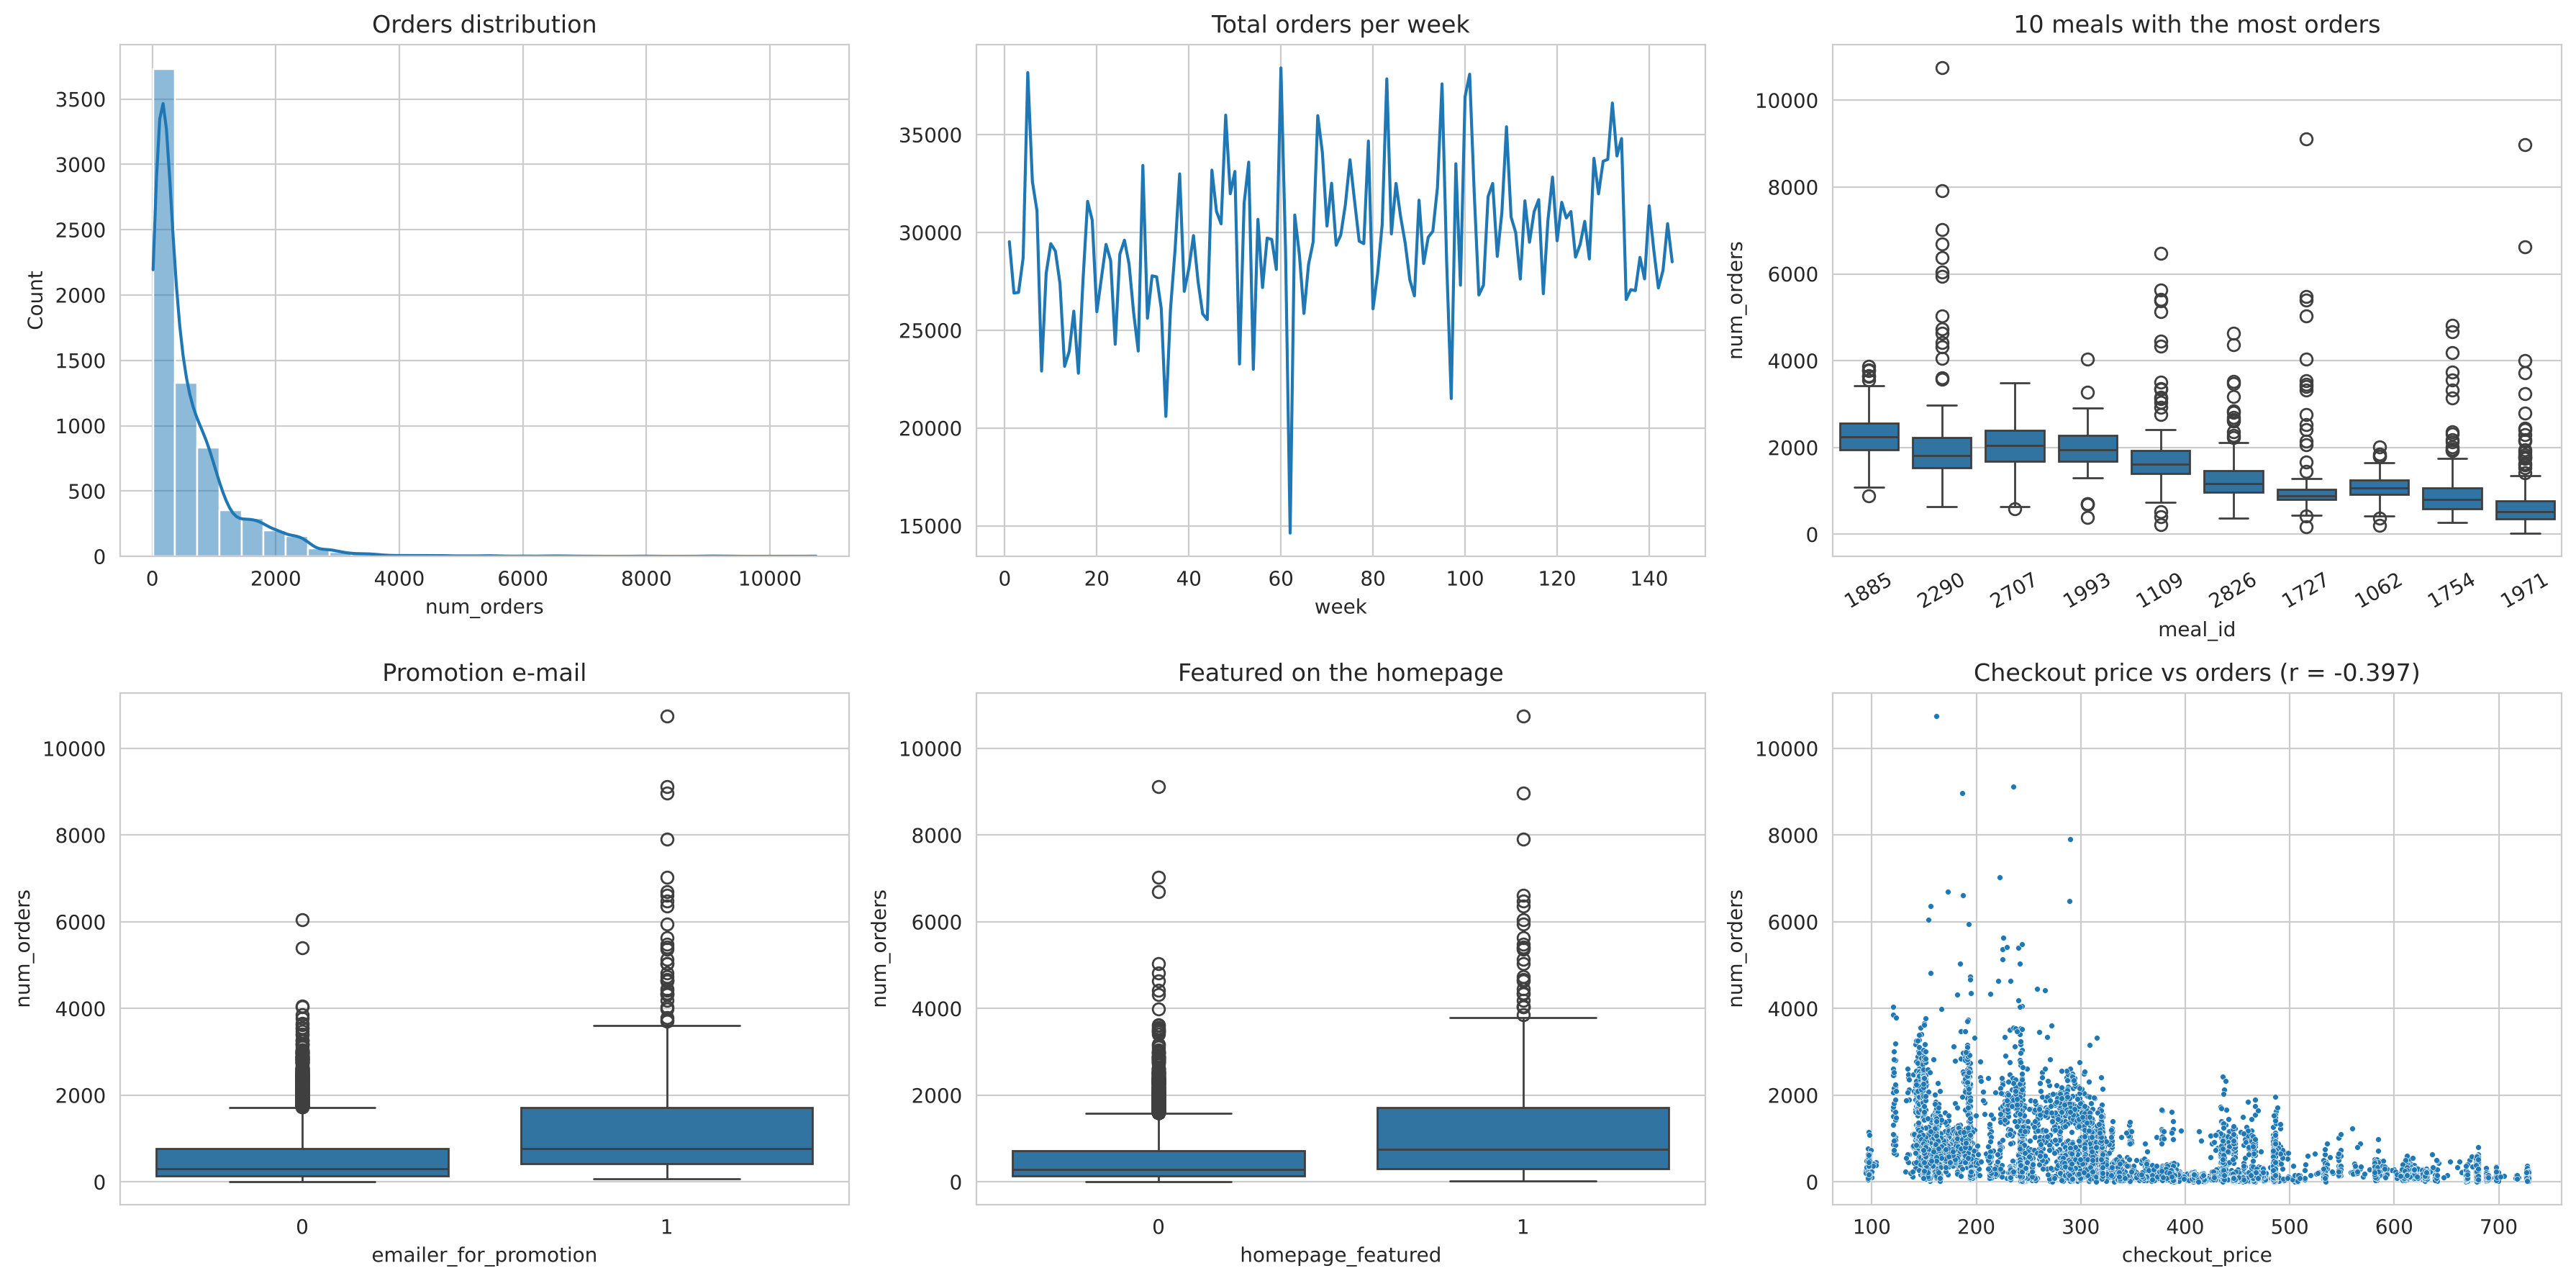

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
# Distribution of weekly orders per meal
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax[0, 0]).set_title("Orders distribution")
# Total orders of the centre in each week
ax[0, 1].plot(df.groupby("week")[TARGET].sum()); ax[0, 1].set(title="Total orders per week", xlabel="week")
# Orders of the 10 meals with the most orders
top = df.groupby("meal_id")[TARGET].sum().nlargest(10).index
sns.boxplot(data=df[df.meal_id.isin(top)], x="meal_id", y=TARGET, order=top, ax=ax[0, 2]).set_title("10 meals with the most orders")
ax[0, 2].tick_params(axis="x", rotation=30)
# Orders with and without each promotion
sns.boxplot(data=df, x="emailer_for_promotion", y=TARGET, ax=ax[1, 0]).set_title("Promotion e-mail")
sns.boxplot(data=df, x="homepage_featured", y=TARGET, ax=ax[1, 1]).set_title("Featured on the homepage")
# Checkout price against orders, with their correlation in the title
sns.scatterplot(data=df, x="checkout_price", y=TARGET, s=8, ax=ax[1, 2]).set_title(
    f"Checkout price vs orders (r = {df[['checkout_price', TARGET]].corr().iloc[0, 1]:.3f})")
plt.tight_layout(); plt.show()

## 4. Encoding, split and scaling
1. Categorical inputs are one-hot encoded (one 0/1 column per category).
2. Rows are split at random into 80 % training and 20 % testing. The split is made on row numbers rather than on the data itself, so Stacking 2 can look up each row's LSTM window (the 10 previous records of its meal) and use exactly the same training and test rows as the other models.
3. Inputs are scaled to 0–1 with a scaler fitted on the training rows only, so no test information enters training. The target stays in orders.

In [7]:
CAT_COLS = ["meal_id"]
NUM_COLS = ["checkout_price", "base_price", "emailer_for_promotion", "homepage_featured"] + LAG_COLS

X = pd.get_dummies(df[CAT_COLS + NUM_COLS], columns=CAT_COLS, dtype=float)    # one-hot encode the categorical columns
y = df[TARGET].to_numpy(dtype=float)

# Random 80/20 split on row positions, so LSTM windows can use the same rows
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Fit the scaler on training predictors only, then apply it to every row
scaler = MinMaxScaler().fit(X.iloc[idx_tr])
X_all  = scaler.transform(X)
X_tr, X_te, y_tr, y_te = X_all[idx_tr], X_all[idx_te], y[idx_tr], y[idx_te]
print(f"{X.shape[1]} inputs | train {X_tr.shape} | test {X_te.shape}")
print(list(X.columns))

58 inputs | train (5636, 58) | test (1410, 58)
['checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'Orders_last_week', 'Orders_last_two_weeks', 'Orders_last_four_weeks', 'meal_id_1062', 'meal_id_1109', 'meal_id_1198', 'meal_id_1207', 'meal_id_1216', 'meal_id_1230', 'meal_id_1247', 'meal_id_1248', 'meal_id_1311', 'meal_id_1438', 'meal_id_1445', 'meal_id_1525', 'meal_id_1543', 'meal_id_1558', 'meal_id_1571', 'meal_id_1727', 'meal_id_1754', 'meal_id_1770', 'meal_id_1778', 'meal_id_1803', 'meal_id_1847', 'meal_id_1878', 'meal_id_1885', 'meal_id_1902', 'meal_id_1962', 'meal_id_1971', 'meal_id_1993', 'meal_id_2104', 'meal_id_2126', 'meal_id_2139', 'meal_id_2290', 'meal_id_2304', 'meal_id_2306', 'meal_id_2322', 'meal_id_2444', 'meal_id_2490', 'meal_id_2492', 'meal_id_2494', 'meal_id_2539', 'meal_id_2569', 'meal_id_2577', 'meal_id_2581', 'meal_id_2631', 'meal_id_2640', 'meal_id_2664', 'meal_id_2704', 'meal_id_2707', 'meal_id_2760', 'meal_id_2826', 'meal_id_2867', 'me

## 5. Evaluation metrics
$MAE=\frac1n\sum|y-\hat y|$ · $MAPE=\frac{100}{n}\sum|\frac{y-\hat y}{y}|$ · $Accuracy=100-MAPE$ · $R^2=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$

`evaluate` turns one model's test predictions into a row of the results table. `results`, `preds` and `truth` collect every model's output for Section 10.

In [8]:
def evaluate(name, y_true, y_pred, secs):
    # One results-table row: error metrics (in orders / %), R2, training time and test-set size
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred), "MAPE (%)": mape,
            "Accuracy (%)": 100 - mape, "R2": r2_score(y_true, y_pred), "Training time (s)": secs,
            "Test rows": len(y_true)}
results, preds, truth = [], {}, {}      # metric rows, test predictions and matching actual values per model

## 6. Individual models: Random Forest, XGBoost, SVR
Each model is tuned by 5-fold grid search on the training set (lowest MAE wins), refitted on all training rows, and evaluated on the test set. The training time covers both the search and the refit. SVR is wrapped so that it learns the target rescaled to a standard deviation of `SVR_TARGET_SD`; its predictions are converted back to orders.

In [9]:
svr_k = y_tr.std() / SVR_TARGET_SD     # factor that rescales the training target to SVR_TARGET_SD

GRIDS = {   # each model with its candidate hyperparameter values
    "RF":      (RandomForestRegressor(random_state=RANDOM_STATE),
                {"n_estimators": [50, 100], "max_depth": [5, 10, 20, None], "min_samples_split": [2, 5]}),
    "XGBoost": (XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
                {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 5, 7]}),
    # SVR (default RBF kernel and gamma) learns the target divided by svr_k; predictions are multiplied back to orders
    "SVR":     (TransformedTargetRegressor(SVR(), func=lambda v: v / svr_k, inverse_func=lambda v: v * svr_k),
                {"regressor__C": [0.1, 1], "regressor__epsilon": [0.1, 0.2]}),
}
best = {}   # tuned model per name, reused by the stacking ensembles
for name, (est, grid) in GRIDS.items():
    # Grid search with 5-fold CV, then refit of the best setting on all training rows (timed together)
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=CV_FOLDS, scoring=SCORING, n_jobs=-1).fit(X_tr, y_tr)
    secs = time.time() - t0
    best[name], preds[name], truth[name] = gs.best_estimator_, gs.predict(X_te), y_te
    results.append(evaluate(name, y_te, preds[name], secs))
    print(f"{name:8s} {gs.best_params_}  ({secs:.1f}s)")

RF       {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}  (51.2s)


XGBoost  {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 100}  (6.1s)


SVR      {'regressor__C': 1, 'regressor__epsilon': 0.1}  (19.3s)


## 7. LSTM
Each sample is a window of the **10 preceding records of the same meal** (all scaled inputs), and the label is the orders at the following record. The rows with 10 earlier records are split 80/20 with the same seed. The test windows are passed as validation data, which only reports a score during training and does not change the model.

In [10]:
def build_lstm(n_features):
    # Two stacked LSTM layers (50 units each) with 20 % dropout after each, then one output neuron
    model = Sequential([Input(shape=(SEQ_LEN, n_features)),
                        LSTM(50, return_sequences=True), Dropout(0.2),
                        LSTM(50, return_sequences=False), Dropout(0.2),
                        Dense(1)])
    model.compile(optimizer="adam", loss="mse")           # Adam with its default learning rate, mean squared error loss
    return model

class LSTMRegressor:
    # Wraps the Keras LSTM with optional 0-1 target scaling; predictions always come back in orders.
    def __init__(self, n_features, scale_target=LSTM_SCALE_TARGET):
        self.n_features, self.scale_target = n_features, scale_target
    def fit(self, W, y, validation_data=None):
        set_seeds()                                        # every LSTM starts from the same random state
        self.ys = MinMaxScaler().fit(y.reshape(-1, 1)) if self.scale_target else None
        f = (lambda v: self.ys.transform(v.reshape(-1, 1)).ravel()) if self.scale_target else (lambda v: v)
        val = None if validation_data is None else (validation_data[0], f(validation_data[1]))
        self.model = build_lstm(self.n_features)
        self.model.fit(W, f(y), epochs=20, batch_size=32, validation_data=val, verbose=0)
        return self
    def predict(self, W):
        p = self.model.predict(W, verbose=0)
        return (self.ys.inverse_transform(p) if self.scale_target else p).ravel()

# Row numbers of the 10 previous records of each row's series. Records before a series' first record are
# padded by repeating that first record (only Stacking 2 needs that, because it must predict every row).
PREV = np.zeros((len(df), SEQ_LEN), dtype=int)
for rows in df.groupby(SERIES).indices.values():          # row numbers of one series, in time order
    for k, r in enumerate(rows):
        PREV[r] = rows[np.clip(np.arange(k - SEQ_LEN, k), 0, None)]
HISTORY = df.groupby(SERIES).cumcount().to_numpy()         # number of earlier records in the same series

def make_windows(days):
    # Window for row t = the 10 previous records of its series
    return np.stack([X_all[PREV[t]] for t in days])

# Complete windows only (rows with 10 earlier records of their meal), split 80/20 with the same seed
days = np.where(HISTORY >= SEQ_LEN)[0]
W, yw = make_windows(days), y[days]
W_tr, W_te, yw_tr, yw_te = train_test_split(W, yw, test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Train (timed), predict the test windows and record the metrics
t0 = time.time()
lstm = LSTMRegressor(W.shape[2]).fit(W_tr, yw_tr, validation_data=(W_te, yw_te))
secs = time.time() - t0
preds["LSTM"], truth["LSTM"] = lstm.predict(W_te), yw_te
results.append(evaluate("LSTM", yw_te, preds["LSTM"], secs))
print(f"LSTM trained in {secs:.1f}s")

LSTM trained in 41.5s


## 8. Stacking 1: RF + XGBoost + SVR → Ridge
The tuned RF, XGBoost and SVR models are combined with scikit-learn's `StackingRegressor`:
1. 5-fold cross-validation produces an out-of-fold prediction from each base model for every training row.
2. A Ridge regression learns how to weight those predictions. It sees only the predictions, not the original inputs.
3. The base models are refitted on all training rows.

Ridge's regularisation strength (`alpha`) is chosen by an outer 5-fold grid search, which rebuilds the whole stack for every candidate value.

In [11]:
t0 = time.time()
# Stack of the tuned base models with a Ridge meta-learner trained on 5-fold out-of-fold predictions
stack = StackingRegressor(estimators=[("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])],
                          final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)
# Outer grid search over Ridge alpha; each candidate rebuilds and scores the whole stack
s1 = GridSearchCV(stack, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                  cv=CV_FOLDS, scoring=SCORING).fit(X_tr, y_tr)
secs = time.time() - t0
preds["Stacking 1"], truth["Stacking 1"] = s1.predict(X_te), y_te
results.append(evaluate("Stacking 1 (RF, XGBoost, SVR)", y_te, preds["Stacking 1"], secs))
print(f"Stacking 1: {s1.best_params_} | Ridge weights [RF, XGB, SVR] = {np.round(s1.best_estimator_.final_estimator_.coef_, 3)} ({secs:.1f}s)")

Stacking 1: {'final_estimator__alpha': 100} | Ridge weights [RF, XGB, SVR] = [0.104 0.791 0.153] (257.4s)


## 9. Stacking 2: RF + XGBoost + SVR + LSTM → Ridge
This uses the same stacking and grid-search procedure as Stacking 1, with the LSTM added as a fourth base model.
* Each row's input is `[row features | flattened 10-record window]`. Column selectors give RF, XGBoost and SVR the row features only, and the LSTM the window only.
* With `STACK2_LSTM_MODE = "prefit"`, the LSTM is trained once on the training rows (included in the training time) and reused inside every fold. `"refit"` trains a new LSTM in every fold instead, which takes much longer.
* The prefit LSTM has already seen the training rows, so the cell after the model compares its accuracy on those rows with its accuracy on unseen test rows.

In [12]:
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.pipeline import Pipeline
from joblib import parallel_backend

STACK2_LSTM_MODE = "prefit"   # "prefit" = LSTM trained once and reused in every fold; "refit" = new LSTM trained in every fold
PREFIT_LSTM = {}              # the once-trained LSTM, looked up by key so sklearn's clone() never copies a Keras model

class ColumnSlice(TransformerMixin, BaseEstimator):
    # Keeps columns [start, stop) of the combined input.
    def __init__(self, start=0, stop=None):
        self.start, self.stop = start, stop
    def fit(self, Z, y=None):
        return self
    def transform(self, Z):
        return Z[:, self.start:self.stop]

class WindowLSTM(RegressorMixin, BaseEstimator):
    # LSTM base model for StackingRegressor; input = flattened 10-record windows.
    # With prefit_key, fit() only attaches the once-trained model; otherwise it trains a new LSTM.
    def __init__(self, n_features=1, prefit_key=None):
        self.n_features, self.prefit_key = n_features, prefit_key
    def _windows(self, Z):
        return Z.reshape(-1, SEQ_LEN, self.n_features)      # flat rows back to (samples, 10 records, features)
    def fit(self, Z, y):
        self.model_ = (PREFIT_LSTM[self.prefit_key] if self.prefit_key
                       else LSTMRegressor(self.n_features).fit(self._windows(Z), y))
        return self
    def predict(self, Z):
        return self.model_.predict(self._windows(Z))

# Combined input: the row's own features followed by its flattened 10-record window
p     = X_all.shape[1]
W_all = make_windows(np.arange(len(y)))                       # every row gets a window (first 10 padded)
Z_all = np.hstack([X_all, W_all.reshape(len(y), -1)])         # [row features | flattened window]
Z_tr, Z_te = Z_all[idx_tr], Z_all[idx_te]
on_day = lambda est: Pipeline([("day_features", ColumnSlice(0, p)), ("model", clone(est))])   # base model on row features only

t0 = time.time()
if STACK2_LSTM_MODE == "prefit":
    PREFIT_LSTM["stack2"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)      # the single LSTM training
# LSTM base model on the window columns only
lstm_base = Pipeline([("window", ColumnSlice(p, None)),
                      ("model", WindowLSTM(p, "stack2" if STACK2_LSTM_MODE == "prefit" else None))])

# Same stacking set-up as Stacking 1, with the LSTM as a fourth base model
stack2 = StackingRegressor(
    estimators=[("rf", on_day(best["RF"])), ("xgb", on_day(best["XGBoost"])), ("svr", on_day(best["SVR"])), ("lstm", lstm_base)],
    final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)     # base models fitted in parallel
# Threads instead of separate processes, so every worker shares the one in-memory Keras model
with parallel_backend("threading"):
    s2 = GridSearchCV(stack2, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                      cv=CV_FOLDS, scoring=SCORING).fit(Z_tr, y_tr)
secs = time.time() - t0
preds["Stacking 2"], truth["Stacking 2"] = s2.predict(Z_te), y_te
results.append(evaluate("Stacking 2 (RF, XGBoost, SVR, LSTM)", y_te, preds["Stacking 2"], secs))
print(f"Stacking 2 ({STACK2_LSTM_MODE}): {s2.best_params_} | Ridge weights [RF, XGB, SVR, LSTM] = "
      f"{np.round(s2.best_estimator_.final_estimator_.coef_, 3)} ({secs:.1f}s)")

Stacking 2 (prefit): {'final_estimator__alpha': 100} | Ridge weights [RF, XGB, SVR, LSTM] = [0.104 0.792 0.114 0.035] (287.6s)


In [13]:
# Prefit LSTM accuracy on the training rows it was trained on (whose predictions train Ridge) vs unseen test rows
if STACK2_LSTM_MODE == "prefit":
    m = PREFIT_LSTM["stack2"]
    tr_hat, te_hat = m.predict(W_all[idx_tr]), m.predict(W_all[idx_te])
    display(pd.DataFrame({f"MAE ({UNIT})": [mean_absolute_error(y_tr, tr_hat), mean_absolute_error(y_te, te_hat)],
                          "R2": [r2_score(y_tr, tr_hat), r2_score(y_te, te_hat)]},
                         index=["Training rows (seen, fed to Ridge)", "Test rows (unseen)"]).round(3))

,MAE (orders),R2
"Training rows (seen, fed to Ridge)",200.996,0.672
Test rows (unseen),207.689,0.679


## 10. Results
These are the test-set metrics for all six models. The LSTM is evaluated on its own test windows (the complete windows split separately); the other models on the test rows.

In [14]:
# Results table: one row per model
res = pd.DataFrame(results).set_index("Model")
display(res.round(3))

,MAE,MAPE (%),Accuracy (%),R2,Training time (s),Test rows
Model,,,,,,
RF,151.655,38.627,61.373,0.851,51.169,1410
XGBoost,151.802,37.529,62.471,0.832,6.144,1410
SVR,165.340,36.887,63.113,0.727,19.261,1410
LSTM,203.243,66.769,33.231,0.642,41.520,1308
"Stacking 1 (RF, XGBoost, SVR)",148.925,35.573,64.427,0.841,257.371,1410
"Stacking 2 (RF, XGBoost, SVR, LSTM)",148.532,35.605,64.395,0.841,287.632,1410


### Actual vs predicted
Left: each test prediction plotted against the actual value (red line = perfect prediction). Right: actual and predicted values across the test samples.

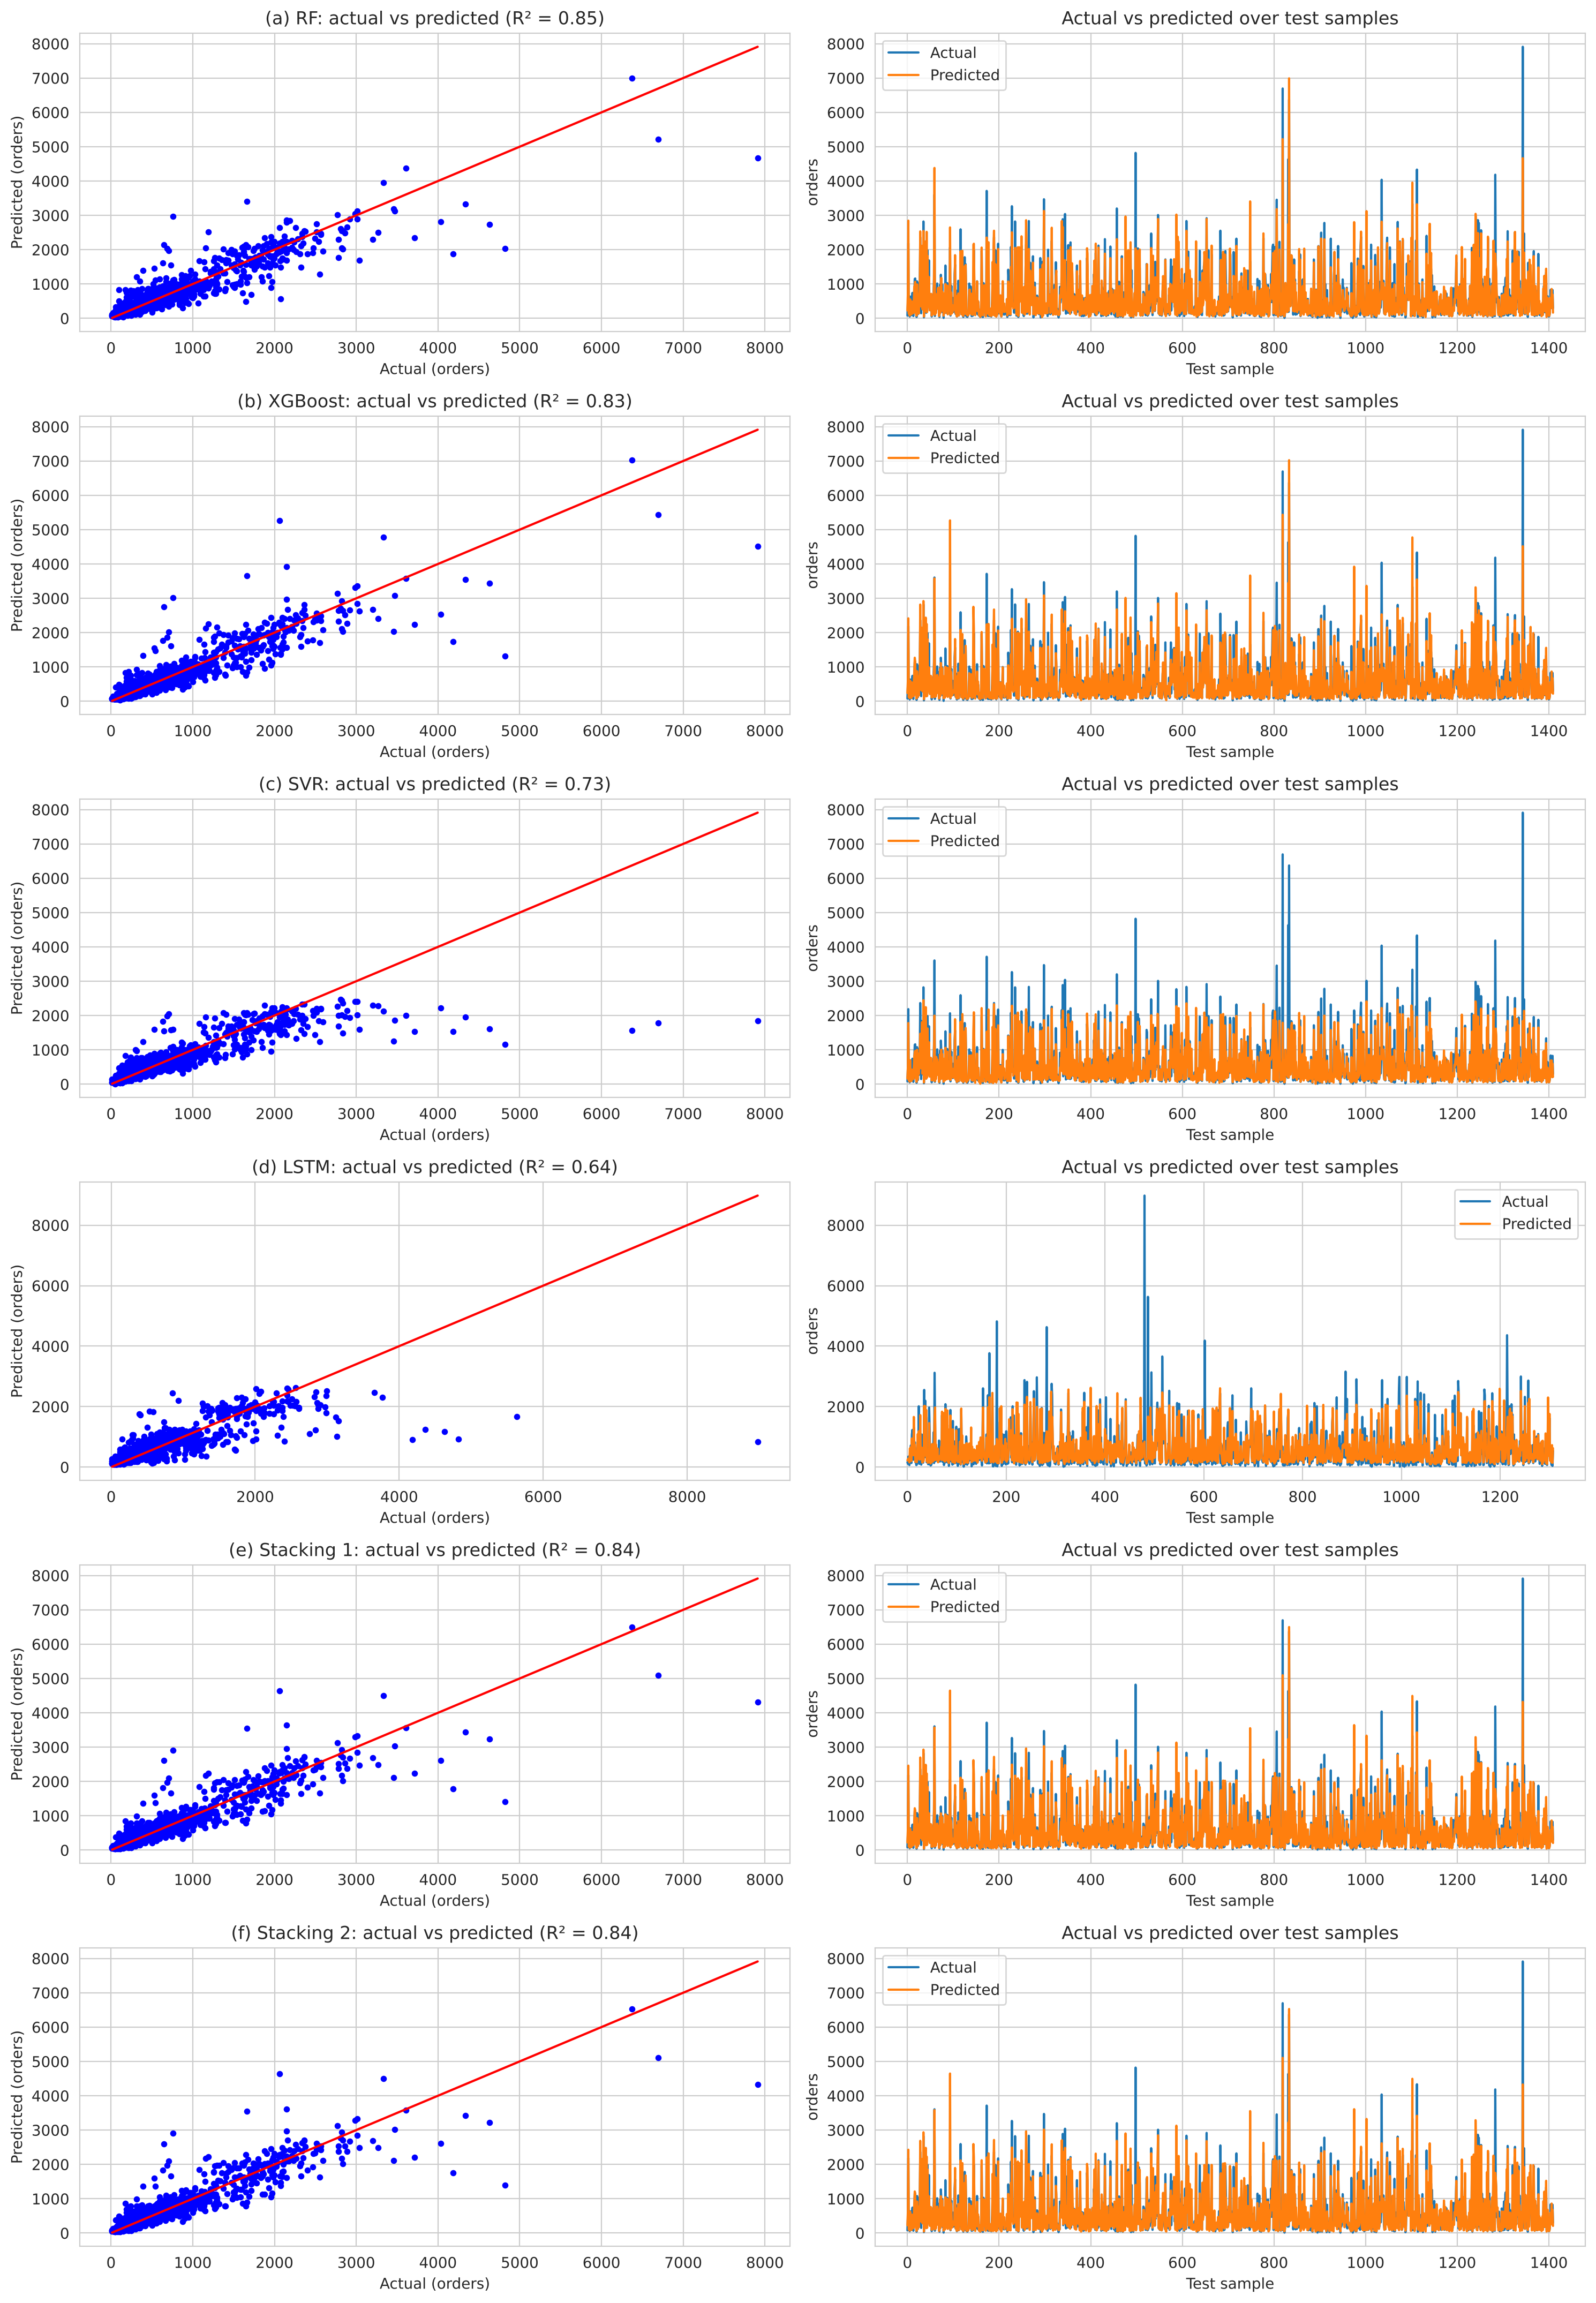

In [15]:
fig, axes = plt.subplots(len(preds), 2, figsize=(15, 3.6 * len(preds)))
for i, (name, p_) in enumerate(preds.items()):
    a = truth[name]; lims = [a.min(), a.max()]
    # Scatter of predicted vs actual with the identity line
    axes[i, 0].scatter(a, p_, s=10, c="blue"); axes[i, 0].plot(lims, lims, "r-")
    axes[i, 0].set(title=f"({'abcdef'[i]}) {name}: actual vs predicted (R² = {r2_score(a, p_):.2f})",
                   xlabel=f"Actual ({UNIT})", ylabel=f"Predicted ({UNIT})")
    # Actual and predicted series over the test samples
    axes[i, 1].plot(a, label="Actual"); axes[i, 1].plot(p_, label="Predicted")
    axes[i, 1].set(title="Actual vs predicted over test samples", xlabel="Test sample", ylabel=UNIT); axes[i, 1].legend()
plt.tight_layout(); plt.show()

### Accuracy vs training time
R² (higher is better) and training time for each model, with the value labelled on each bar.

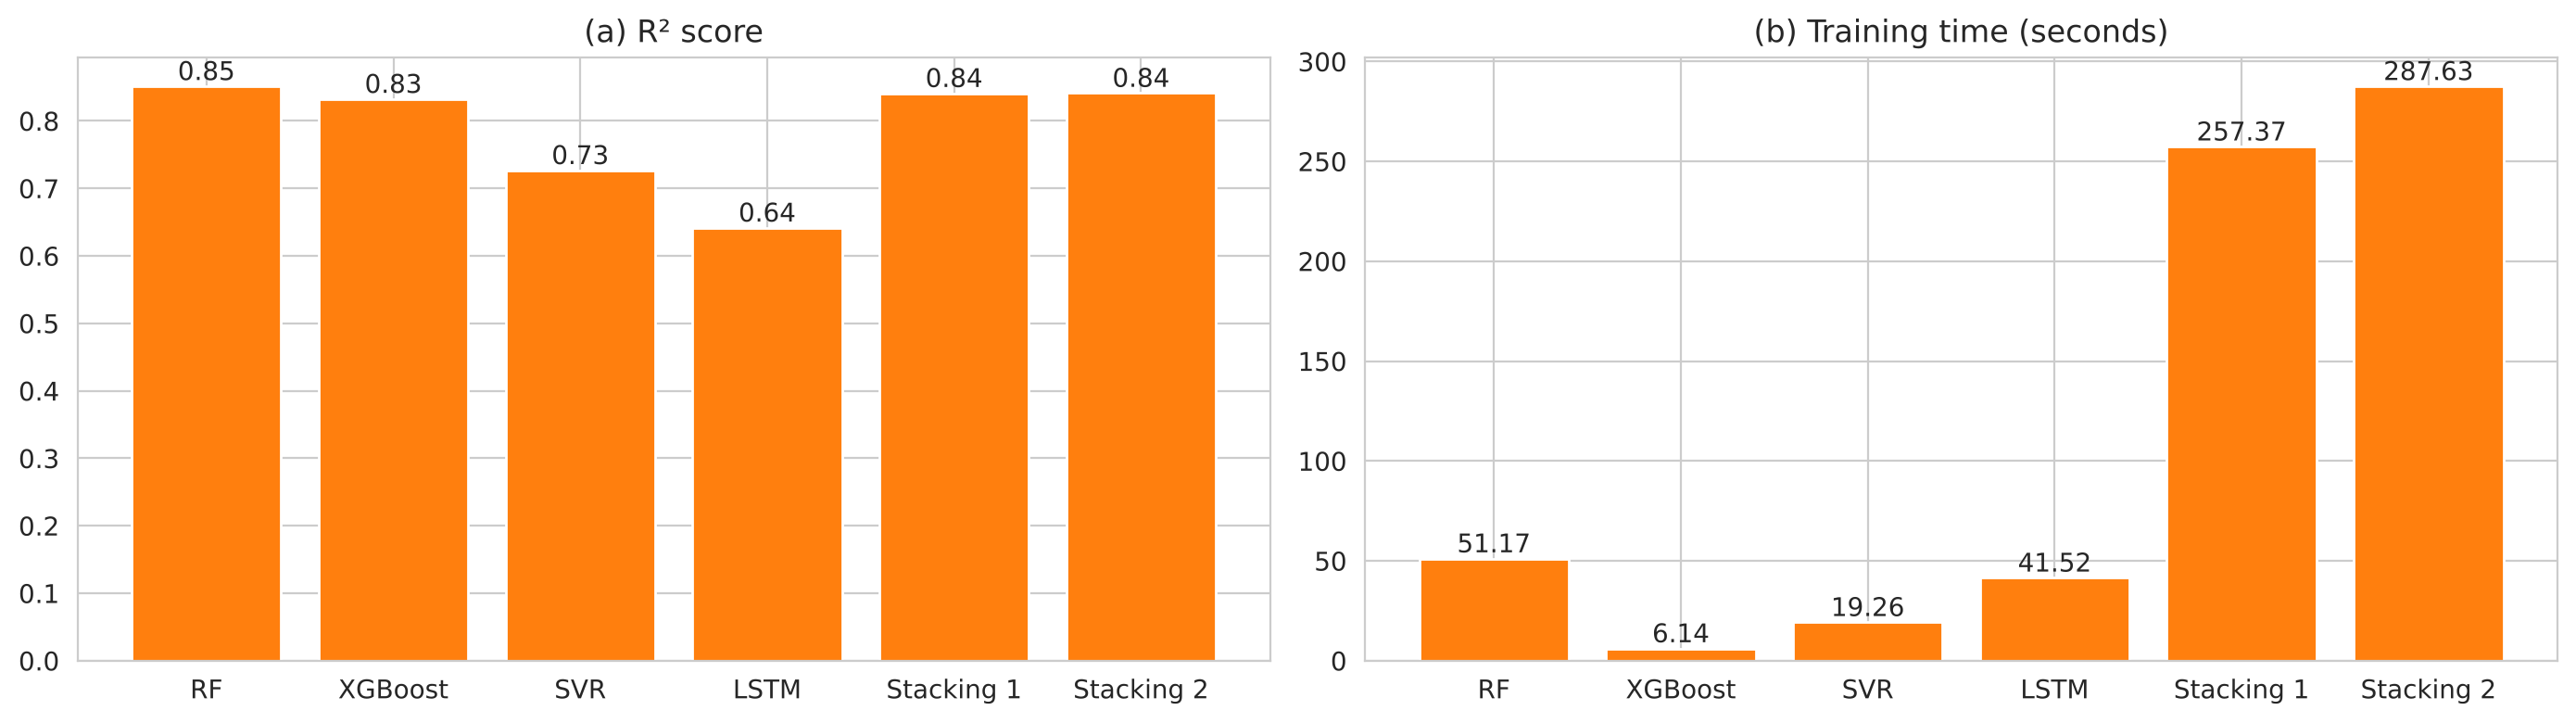

In [16]:
t = res.rename(index=lambda s: s.split(" (")[0])        # short model names for the x-axis
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, title in [(ax[0], "R2", "(a) R² score"), (ax[1], "Training time (s)", "(b) Training time (seconds)")]:
    a.bar(t.index, t[col], color="tab:orange"); a.set_title(title)
    for x, v in enumerate(t[col]): a.annotate(f"{v:.2f}", (x, v), ha="center", va="bottom")
plt.tight_layout(); plt.show()